In [1]:
# ============================================================
# E-Commerce 360° Business Intelligence
# ============================================================
#
# STEP 04 — STATISTICAL ANALYSIS
#
# Business objective:
# Use statistics to understand product prices, freight charges,
# customer reviews and delivery performance.
#
# We will calculate descriptive statistics, examine correlations
# and perform a simple statistical test.
#
# Important:
# A statistical relationship does not automatically prove
# that one factor causes another.
#
# ============================================================

In [2]:
# ============================================================
# WHAT YOU WILL LEARN
# ============================================================
#
# 1. Mean, median and standard deviation.
#
# 2. Product price analysis.
#
# 3. Pearson correlation.
#
# 4. Customer review statistics.
#
# 5. Delivery performance comparison.
#
# 6. Hypothesis testing using Welch's t-test.
#
# 7. Monthly revenue statistics.
#
# ============================================================
# HOW TO RUN
# ============================================================
#
# Step 1: Open 04_statistical_analysis.ipynb.
#
# Step 2: Click on the + Markdown button.
#
# Step 3: Paste this complete documentation.
#
# Step 4: Press Shift + Enter to render the Markdown cell.
#
# Step 5: Click + Code to create a new Python code cell.
#
# Step 6: Write your statistical analysis Python code.
#
# Step 7: Press Shift + Enter to execute the code.
#
# Step 8: Check the output, tables and graphs.
#
# ============================================================
# END OF SECTION
# ============================================================

In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

# Set chart style
sns.set_theme(style="whitegrid")

# Display more columns
pd.set_option("display.max_columns", 100)

In [4]:
# Set dataset folder path
DATASET_DIR = Path("dataset")

# Load CSV files
orders = pd.read_csv(DATASET_DIR / "olist_orders_dataset.csv")
items = pd.read_csv(DATASET_DIR / "olist_order_items_dataset.csv")
reviews = pd.read_csv(DATASET_DIR / "olist_order_reviews_dataset.csv")

# Display dataset shapes
print("Orders:", orders.shape)
print("Items:", items.shape)
print("Reviews:", reviews.shape)

# Display first five rows
display(orders.head())
display(items.head())
display(reviews.head())

Orders: (99441, 8)
Items: (112650, 7)
Reviews: (99224, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [7]:
# Cell 3 — Data preprocessing

# Convert date columns into datetime format
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"], errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"], errors="coerce"
)

# Calculate order-level product revenue and freight
order_values = items.groupby("order_id").agg(
    product_revenue=("price", "sum"),
    freight_value=("freight_value", "sum")
).reset_index()

# Display results
display(order_values.head())

,order_id,product_revenue,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14


In [8]:
#   Cell 4 — Mean, Median and Standard Deviation

# Calculate statistical values
mean_price = items["price"].mean()
median_price = items["price"].median()
std_price = items["price"].std()

# Display results
print("Mean Price:", round(mean_price, 2))
print("Median Price:", round(median_price, 2))
print("Standard Deviation:", round(std_price, 2))
print("Minimum Price:", items["price"].min())
print("Maximum Price:", items["price"].max())

Mean Price: 120.65
Median Price: 74.99
Standard Deviation: 183.63
Minimum Price: 0.85
Maximum Price: 6735.0


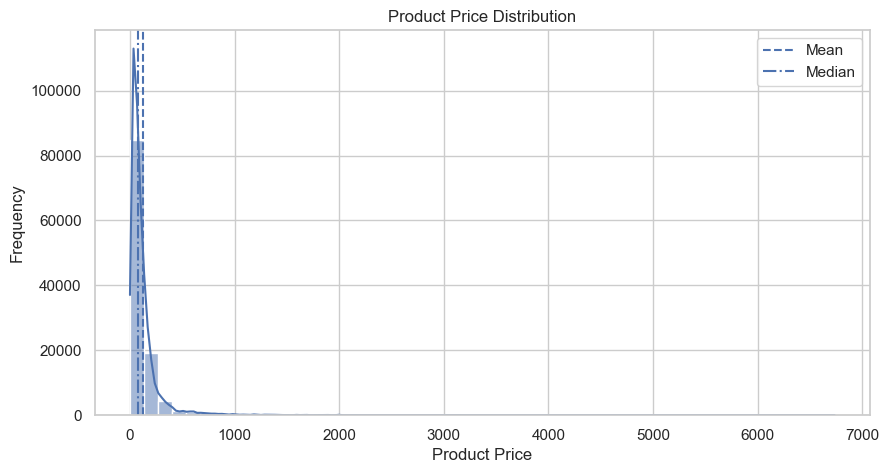

In [9]:
# vCell 5 — Product price distribution

# Create histogram
plt.figure(figsize=(10, 5))

sns.histplot(items["price"], bins=50, kde=True)

plt.axvline(mean_price, linestyle="--", label="Mean")
plt.axvline(median_price, linestyle="-.", label="Median")

plt.title("Product Price Distribution")
plt.xlabel("Product Price")
plt.ylabel("Frequency")
plt.legend()

plt.show()

In [10]:
# Cell 6 — Pearson correlation

# Select price and freight columns
correlation_data = items[["price", "freight_value"]].dropna()

# Calculate Pearson correlation
correlation, p_value = stats.pearsonr(
    correlation_data["price"],
    correlation_data["freight_value"]
)

# Display results
print("Pearson Correlation:", round(correlation, 4))
print("P-value:", p_value)

# Interpret correlation
if correlation > 0:
    print("Positive relationship")
elif correlation < 0:
    print("Negative relationship")
else:
    print("No linear relationship")

Pearson Correlation: 0.4142
P-value: 0.0
Positive relationship


count    99224.000000
mean         4.086421
std          1.347579
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64


review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

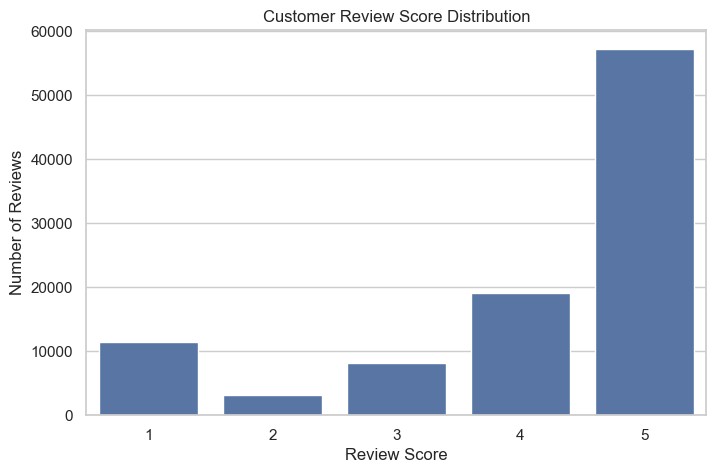

In [11]:
# Cell 7 — Customer review statistics

# Calculate review statistics
print(reviews["review_score"].describe())

# Count each review score
review_counts = reviews["review_score"].value_counts().sort_index()

display(review_counts)

# Visualize review scores
plt.figure(figsize=(8, 5))

sns.countplot(data=reviews, x="review_score")

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.show()

In [12]:
# Cell 8 — Delivery performance

# Remove rows with missing delivery dates
delivery_data = orders.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

# Calculate delivery time in days
delivery_data["delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Identify on-time and late orders
delivery_data["delivery_status"] = np.where(
    delivery_data["order_delivered_customer_date"]
    <= delivery_data["order_estimated_delivery_date"],
    "On Time",
    "Late"
)

# Calculate delivery statistics
delivery_summary = delivery_data.groupby(
    "delivery_status"
)["delivery_days"].agg(["count", "mean", "median", "std"])

display(delivery_summary.round(2))

,count,mean,median,std
delivery_status,,,,
Late,7827,31.52,29.16,17.26
On Time,88649,10.88,9.73,6.19


In [13]:
# Cell 9 — Welch's t-test

# Get on-time delivery days
on_time = delivery_data.loc[
    delivery_data["delivery_status"] == "On Time",
    "delivery_days"
].dropna()

# Get late delivery days
late = delivery_data.loc[
    delivery_data["delivery_status"] == "Late",
    "delivery_days"
].dropna()

# Perform Welch's t-test
t_stat, p_value = stats.ttest_ind(
    on_time,
    late,
    equal_var=False
)

# Display results
print("T-statistic:", t_stat)
print("P-value:", p_value)

# Interpret result
if p_value < 0.05:
    print("Significant difference in delivery duration.")
else:
    print("No statistically significant difference detected.")

T-statistic: -105.1777580561632
P-value: 0.0
Significant difference in delivery duration.


In [15]:
# Cell 10 — Monthly revenue analysis

# Merge order information with product revenue
revenue_data = orders.merge(
    order_values,
    on="order_id",
    how="left"
)

# Keep delivered orders
revenue_data = revenue_data[
    revenue_data["order_status"] == "delivered"
].copy()

# Extract month
revenue_data["month"] = (
    revenue_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Calculate monthly revenue
monthly_revenue = revenue_data.groupby(
    "month"
)["product_revenue"].sum().reset_index()

# Display monthly revenue
display(monthly_revenue.head(10))

# Calculate statistics
print(monthly_revenue["product_revenue"].describe())

,month,product_revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40
5,2017-03,359198.85
6,2017-04,340669.68
7,2017-05,489338.25
8,2017-06,421923.37
9,2017-07,481604.52


count        23.000000
mean     574847.743913
std      337263.532856
min          10.900000
25%      349934.265000
50%      607399.670000
75%      862015.660000
max      987765.370000
Name: product_revenue, dtype: float64


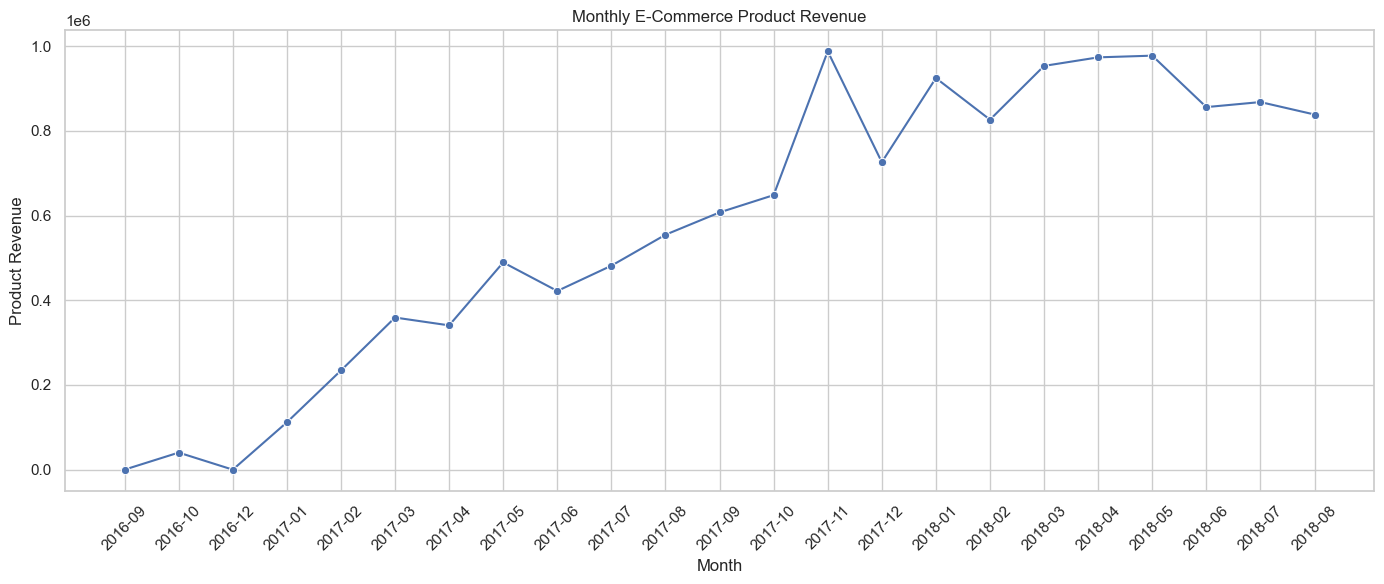

In [17]:
# Cell 11 - Monthly Revenue Chart

# Convert month column into string format
monthly_revenue["month"] = monthly_revenue["month"].astype(str)

# Create monthly revenue chart
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="month",
    y="product_revenue",
    marker="o"
)

# Add chart title and labels
plt.title("Monthly E-Commerce Product Revenue")
plt.xlabel("Month")
plt.ylabel("Product Revenue")

# Rotate month labels
plt.xticks(rotation=45)

# Adjust chart layout
plt.tight_layout()

# Save chart
plt.savefig("screenshots/04_monthly_revenue.png", dpi=300)

# Display chart
plt.show()